# Preparing the Data

In [2]:
# importing libraries

from sklearn.datasets import fetch_openml 
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import accuracy_score
from sklearn.model_selection import (
    cross_val_score,                            
    RepeatedStratifiedKFold,                    
)
import matplotlib.pyplot as plt
import numpy as np

In [3]:
#importing the MNIST dataset
#naming the data as X for the images, and y for the label

mnist = fetch_openml('mnist_784', version=1)
X = mnist.data
y = mnist.target



## I wanted to check how the data looks

In [5]:
# Turning the data into an array
X_array = np.array(X)
y_array = np.array(y)

# Reshaping it into 28X28 Pixels
image_to_show = X_array[0].reshape(28, 28)

# Naming the label
label_of_image = y_array[0]

In [4]:
X.head(5)

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
y.head(5)

0    5
1    0
2    4
3    1
4    9
Name: class, dtype: category
Categories (10, object): ['0', '1', '2', '3', ..., '6', '7', '8', '9']

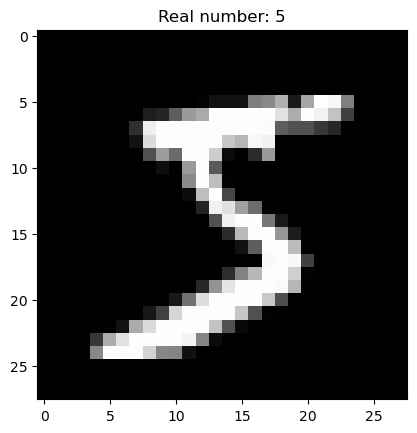

In [6]:
# Showing the image

plt.imshow(image_to_show, cmap='gray')
plt.title(f"Real number: {label_of_image}")
plt.show()

## Splitting the data into training and test set

In [6]:
X_train = X_array[:60000]
y_train = y_array[:60000]
X_test = X_array[60000:]
y_test = y_array[60000:]

## Building the model

In [8]:
clf = DecisionTreeClassifier()

In [9]:
clf.fit(X_train, y_train)

DecisionTreeClassifier()

In [10]:
predictions = clf.predict(X_test)

accuracy_score(y_test, predictions)

0.8761

## Checking where our model is predecting wrong

Model has done wrong 1239 Image out of 10k


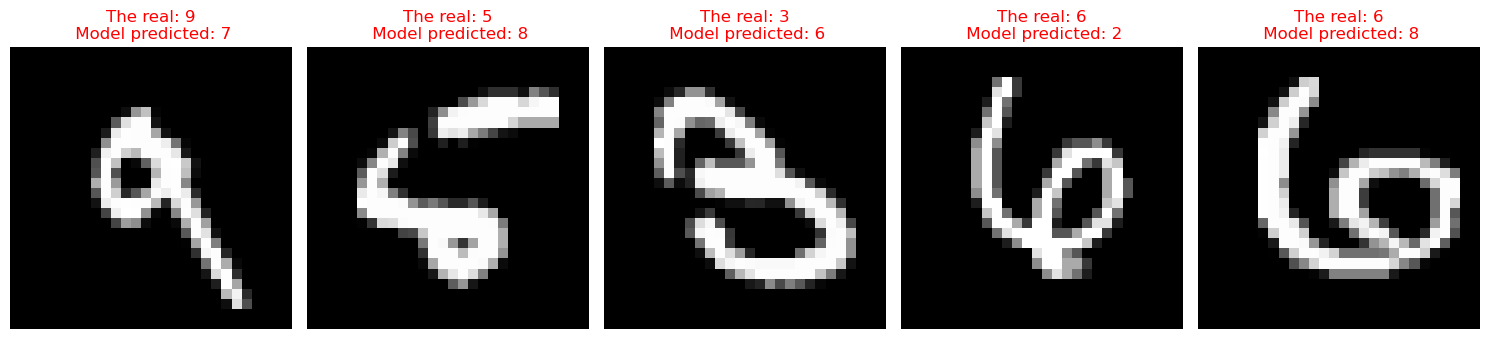

In [11]:
wrong_indices = np.where(predictions != y_test)[0]

print(f"Model has done wrong {len(wrong_indices)} Image out of 10k")

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for i, idx in enumerate(wrong_indices[:5]):
    image = X_test[idx].reshape(28, 28)
    
    axes[i].imshow(image, cmap='gray')
    
    true_label = y_test[idx]
    predicted_label = predictions[idx]
    axes[i].set_title(f"The real: {true_label}\n Model predicted: {predicted_label}", color='red')
    
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## Now ill try to improve our model by trying different depth values

In [12]:
clf = DecisionTreeClassifier(max_depth=2)
cross_val_score(clf, X_train, y_train, cv=5) 

array([0.34158333, 0.334     , 0.34333333, 0.33741667, 0.34583333])

In [13]:
kfold = RepeatedStratifiedKFold(n_splits=5)

In [15]:
for k in range(1, 20):
    clf = DecisionTreeClassifier(max_depth=k)
    scores = cross_val_score(clf, X_train, y_train, cv=kfold)
    print('depth: {}: {}'.format(k, scores.mean()))

depth: 1: 0.19757666666666665
depth: 2: 0.33998333333333336
depth: 3: 0.48025999999999996
depth: 4: 0.5955033333333334
depth: 5: 0.6723033333333334
depth: 6: 0.7349166666666666
depth: 7: 0.7789016666666666
depth: 8: 0.811395
depth: 9: 0.8369
depth: 10: 0.8537250000000001
depth: 11: 0.86267
depth: 12: 0.8681600000000002
depth: 13: 0.8703916666666669
depth: 14: 0.8714466666666665
depth: 15: 0.8715299999999999
depth: 16: 0.8712949999999999
depth: 17: 0.8705266666666666
depth: 18: 0.8705466666666666
depth: 19: 0.8701333333333333


In [7]:
clf = DecisionTreeClassifier(max_depth=15)
clf.fit(X_train, y_train)
predictions = clf.predict(X_test)
accuracy_score(y_test, predictions)

0.8821